Device: cpu
X shape: (2000, 75)
y shape: (2000,)

5 domain đầu tiên:
newmarketholidays.co.uk 0
mos5v34fk.biz 1
gabriellemontgomery.net 1
mapei.group 0
chinaedu.net 0

Train: 1600
Test: 400


Loading weights: 100%|██████████| 71/71 [00:00<00:00, 11966.39it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: huawei-noah/TinyBERT_General_4L_312D
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.weight          | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.bias            | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.596173,0.509058,0.855000,0.828704,0.895000,0.860577
2,0.439149,0.445230,0.860000,0.836449,0.895000,0.864734


/home/ubuntu/.local/lib/python3.10/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/home/ubuntu/.local/lib/python3.10/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Bình thường       0.89      0.82      0.85       200
         DGA       0.84      0.90      0.86       200

    accuracy                           0.86       400
   macro avg       0.86      0.86      0.86       400
weighted avg       0.86      0.86      0.86       400



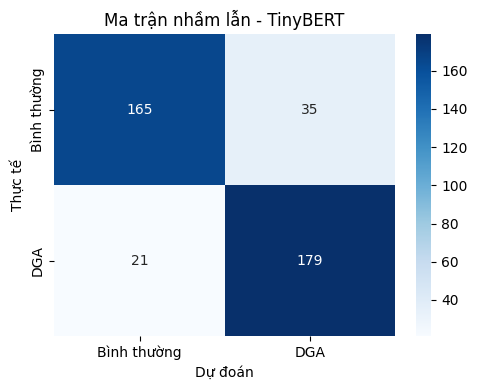

In [4]:
# ============================================================
# DGA DETECTION USING TINYBERT
# ============================================================

import numpy as np
import torch
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments
)

from datasets import Dataset

# =========================
# 1. DEVICE
# =========================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# =========================
# 2. LOAD DATA
# =========================
root = Path.cwd()
data = np.load(
    root / "Dataset" / "1000_dga_dataset_binary.npz",
    allow_pickle=True
)

X = data["X"]
y = data["y"]
char2idx = data["char2idx"].item()

print("X shape:", X.shape)
print("y shape:", y.shape)

# =========================
# 3. DECODE DOMAIN
# =========================
idx2char = {v: k for k, v in char2idx.items()}

domains = []

for row in X:
    domain = "".join(
        idx2char[idx]
        for idx in row
        if idx != 0
    )

    domains.append(domain)

print("\n5 domain đầu tiên:")

for i in range(5):
    print(domains[i], y[i])

# =========================
# 4. TRAIN TEST SPLIT
# =========================
train_texts, test_texts, train_labels, test_labels = train_test_split(
    domains,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("\nTrain:", len(train_texts))
print("Test:", len(test_texts))

# =========================
# 5. LOAD TINYBERT
# =========================
MODEL_NAME = "huawei-noah/TinyBERT_General_4L_312D"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
).to(device)

# =========================
# 6. TOKENIZATION
# =========================
train_encodings = tokenizer(
    train_texts,
    truncation=True,
    padding=True,
    max_length=64
)

test_encodings = tokenizer(
    test_texts,
    truncation=True,
    padding=True,
    max_length=64
)

train_dataset = Dataset.from_dict({
    "input_ids": train_encodings["input_ids"],
    "attention_mask": train_encodings["attention_mask"],
    "labels": train_labels
})

test_dataset = Dataset.from_dict({
    "input_ids": test_encodings["input_ids"],
    "attention_mask": test_encodings["attention_mask"],
    "labels": test_labels
})

# =========================
# 7. METRICS
# =========================
def compute_metrics(eval_pred):
    preds = np.argmax(eval_pred.predictions, axis=-1)

    return {
        "accuracy": accuracy_score(test_labels, preds),
        "precision": precision_score(test_labels, preds),
        "recall": recall_score(test_labels, preds),
        "f1": f1_score(test_labels, preds)
    }

# =========================
# 8. TRAINING CONFIG
# =========================
training_args = TrainingArguments(
    output_dir="./tinybert_dga",

    eval_strategy="epoch",
    save_strategy="no",

    learning_rate=2e-5,
    num_train_epochs=2,

    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,

    weight_decay=0.01,

    logging_steps=20,

    fp16=torch.cuda.is_available(),

    load_best_model_at_end=False,
    report_to="none"
)

# =========================
# 9. TRAINER
# =========================
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics
)

# =========================
# 10. TRAIN
# =========================
trainer.train()

# =========================
# 11. PREDICT
# =========================
predictions = trainer.predict(test_dataset)

y_pred = np.argmax(
    predictions.predictions,
    axis=1
)

# =========================
# 12. CLASSIFICATION REPORT
# =========================
print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        test_labels,
        y_pred,
        target_names=["Bình thường", "DGA"]
    )
)

# =========================
# 13. CONFUSION MATRIX
# =========================
cm = confusion_matrix(test_labels, y_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Bình thường', 'DGA'],
    yticklabels=['Bình thường', 'DGA']
)

plt.title("Ma trận nhầm lẫn - TinyBERT")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")

plt.tight_layout()
plt.show()